*Описание задачи*

Задача: Предсказать, будет ли доставка заказа опоздавшей (late_delivery = 1) или нет (late_delivery = 0), на основе информации о заказе, ресторане, погоде, трафике и курьере.

Тип задачи: Бинарная классификация.

Целевой признак: late_delivery (0 или 1).

Признаки: Все остальные колонки, кроме тех, что напрямую связаны с результатом доставки (например, actual_delivery_time_minutes, order_status, cancellation_reason, customer_rating). Также исключаем идентификаторы (order_id, customer_id и т.д.), так как они не несут полезной информации. Признаки restaurant_preparation_time_minutes и estimated_delivery_time_minutes оставлены: модель прогнозирует опоздание в момент, когда ресторан уже сообщил время приготовления и системе известно расчётное время доставки (перед выездом курьера). Фактическое время доставки, статус заказа, причина отмены и оценка клиента становятся известны только после доставки, поэтому они исключены.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

url = "https://raw.githubusercontent.com/AzotEye/ML/main/food_delivery_orders_dataset.csv"
data = pd.read_csv(url)

Удалим строки без таргета (отмененные заказы)

In [3]:
data = data.dropna(subset=['late_delivery'])
print("После удаления пропусков в late_delivery:", data.shape)

# Проверим, что осталось
print(data.isnull().sum())
print(data['late_delivery'].value_counts(normalize=True))


После удаления пропусков в late_delivery: (49132, 37)
order_id                                   0
customer_id                                0
restaurant_id                              0
driver_id                                  0
order_timestamp                            0
order_date                                 0
order_hour                                 0
day_of_week                                0
is_weekend                                 0
city                                       0
delivery_area                              0
customer_age                               0
customer_type                              0
restaurant_type                            0
restaurant_primary_category                0
restaurant_rating                          0
items_count                                0
subtotal                                   0
discount_percent                           0
tax_amount                                 0
service_fee                                0
d

Уберем утечки и ненужное
- actual_delivery_time — следствие late_delivery (если опоздал — время большое)
- order_status и cancellation_reason — тоже следствие
- customer_rating — ставится после доставки
- id — не несут информации
- order_timestamp, order_date — есть order_hour, day_of_week, is_weekend

In [4]:
cols_to_drop = [
    'order_id', 'customer_id', 'restaurant_id', 'driver_id',
    'order_timestamp', 'order_date',
    'actual_delivery_time_minutes',
    'order_status', 'cancellation_reason',
    'customer_rating'
]
data = data.drop(columns=cols_to_drop)
print("После удаления лишних колонок:", data.shape)
data['late_delivery'] = data['late_delivery'].astype(int)

После удаления лишних колонок: (49132, 27)


Разбиение на train/test

In [5]:
X = data.drop('late_delivery', axis=1)
y = data['late_delivery']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Доли классов в train:", y_train.value_counts(normalize=True).values)
print("Доли классов в test:", y_test.value_counts(normalize=True).values)

Train: (39305, 26) Test: (9827, 26)
Доли классов в train: [0.63429589 0.36570411]
Доли классов в test: [0.63427292 0.36572708]


Разделим на категорианльные и числовые признаки

In [6]:
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Категориальные:", categorical_features)
print("Числовые:", numeric_features)

Категориальные: ['day_of_week', 'city', 'delivery_area', 'customer_type', 'restaurant_type', 'restaurant_primary_category', 'payment_method', 'weather', 'traffic_level']
Числовые: ['order_hour', 'is_weekend', 'customer_age', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'tip_amount', 'distance_km', 'delivery_partner_experience_months', 'delivery_partner_rating', 'restaurant_preparation_time_minutes', 'estimated_delivery_time_minutes']


*Визуализация*

Корреляционная матрица числовых признаков

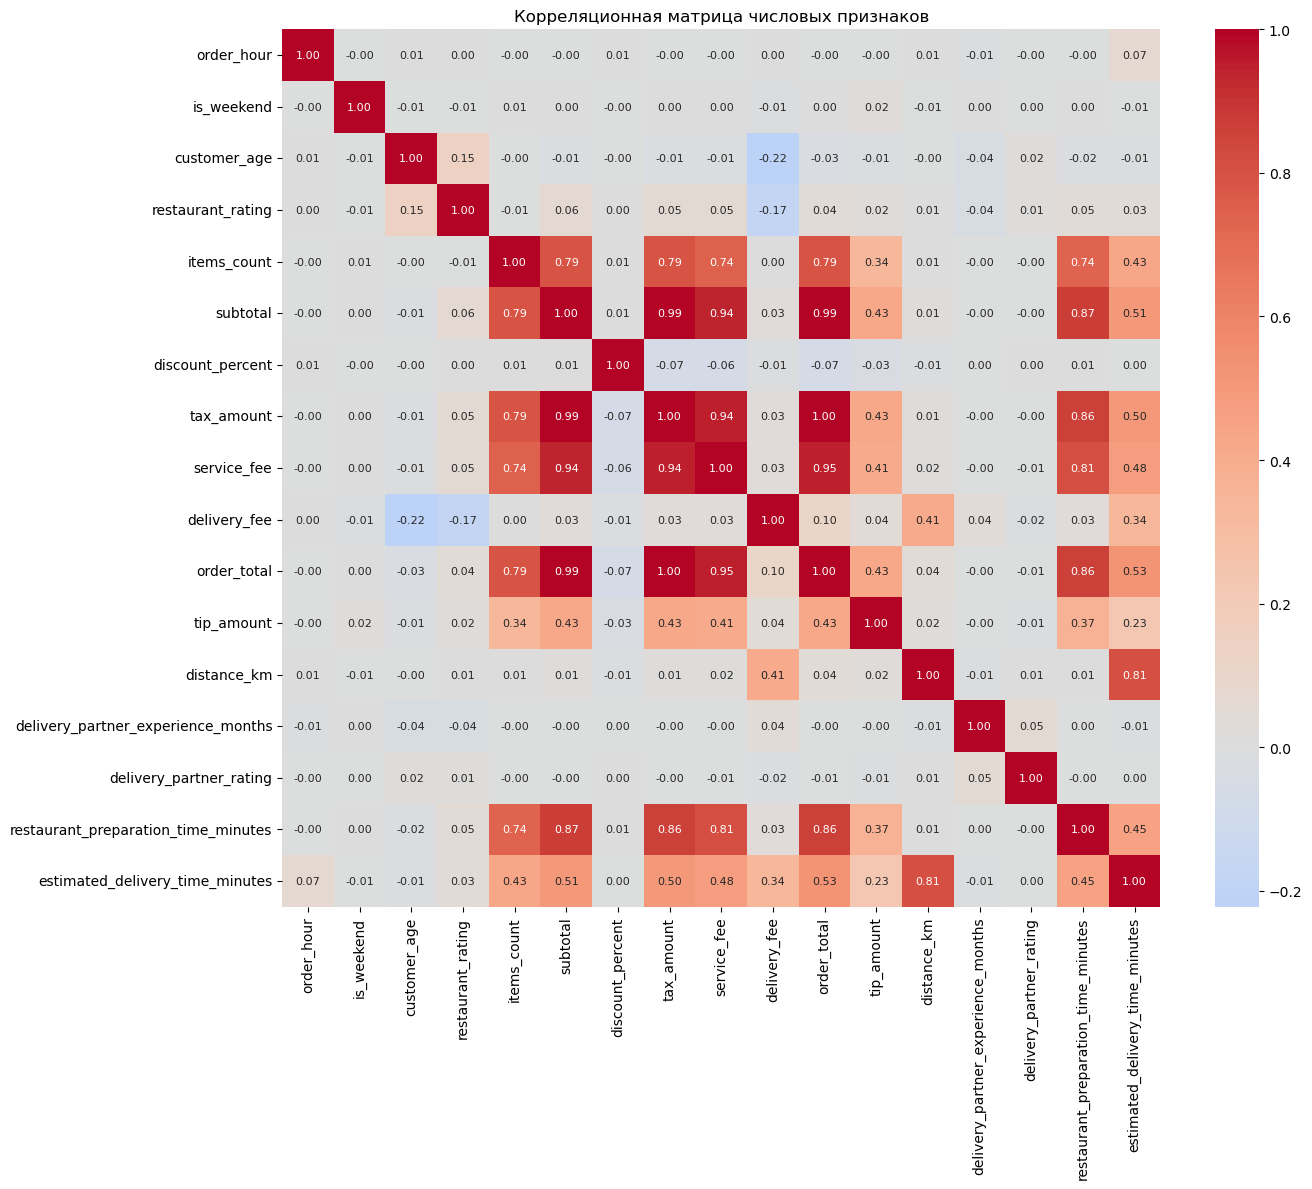

In [7]:
plt.figure(figsize=(14, 12))
corr_matrix = X_train[numeric_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            annot_kws={'size': 8})
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

In [8]:
corr_df = X_train[numeric_features].copy()
corr_df['late_delivery'] = y_train
corr_with_target = corr_df.corr()['late_delivery'].drop('late_delivery').sort_values(ascending=False)
print(corr_with_target)

restaurant_preparation_time_minutes    0.255817
distance_km                            0.095248
estimated_delivery_time_minutes        0.086677
delivery_fee                           0.062336
order_hour                             0.010836
delivery_partner_experience_months     0.009647
order_total                            0.007024
service_fee                            0.002901
tax_amount                             0.002369
subtotal                               0.001937
items_count                            0.001931
delivery_partner_rating               -0.000129
tip_amount                            -0.004989
discount_percent                      -0.005229
restaurant_rating                     -0.012026
customer_age                          -0.014216
is_weekend                            -0.073338
Name: late_delivery, dtype: float64


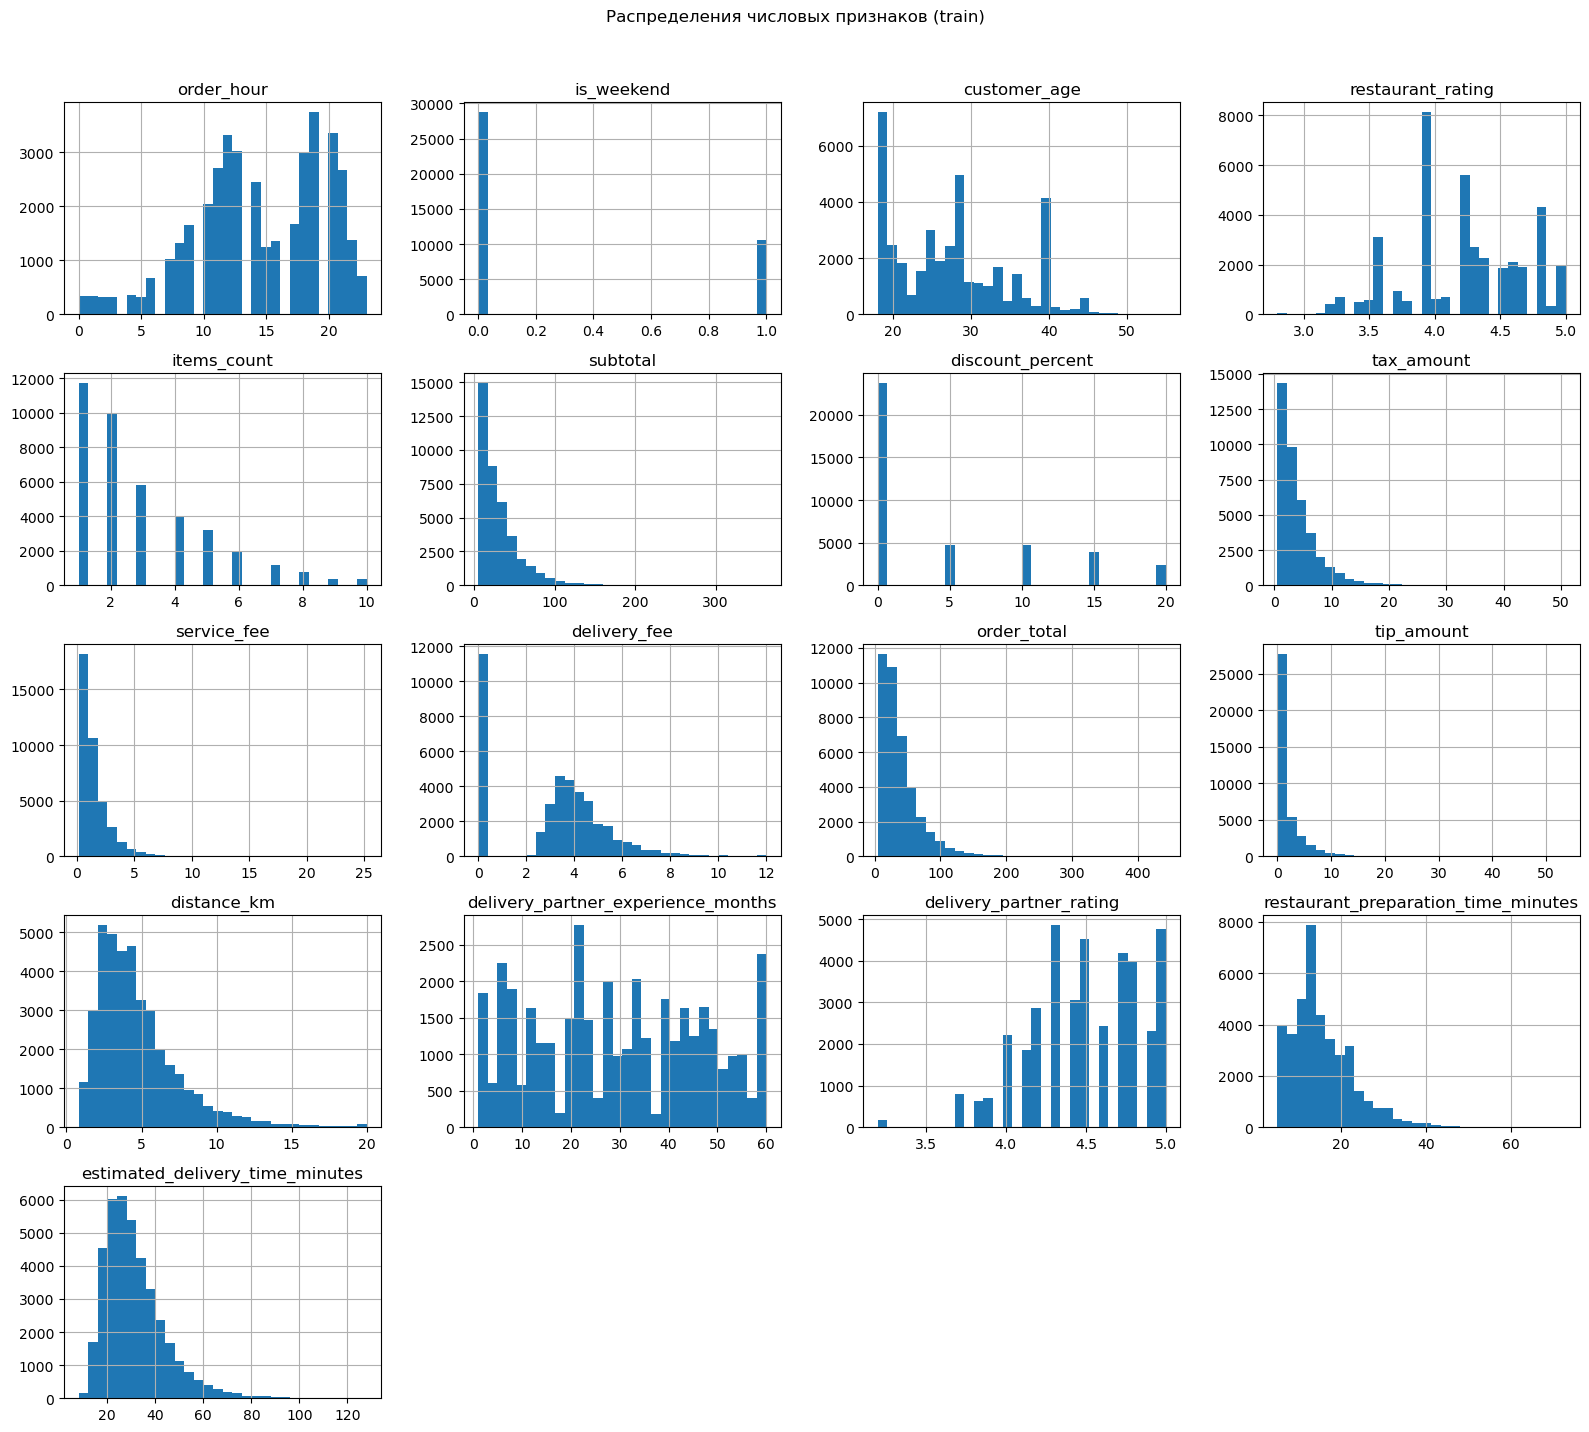

In [9]:
X_train[numeric_features].hist(figsize=(16, 14), bins=30)
plt.suptitle('Распределения числовых признаков (train)', y=1.02)
plt.tight_layout()
plt.show()

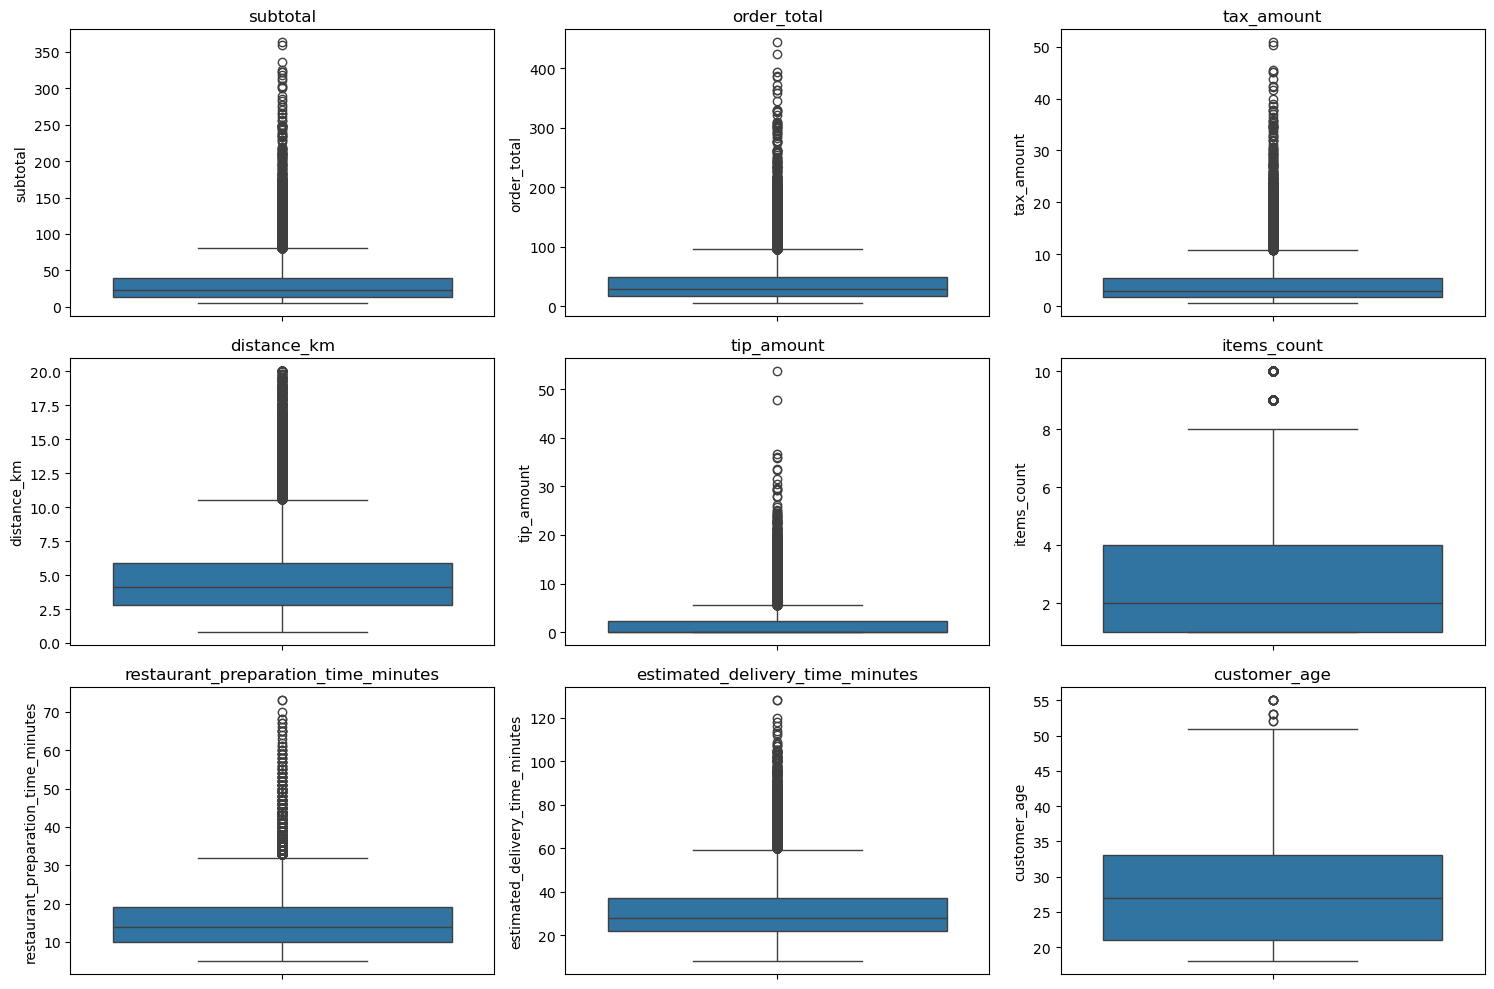

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
cols_to_check = ['subtotal', 'order_total', 'tax_amount', 'distance_km',
                 'tip_amount', 'items_count', 'restaurant_preparation_time_minutes',
                 'estimated_delivery_time_minutes', 'customer_age']
for ax, col in zip(axes.flatten(), cols_to_check):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [11]:
for col in categorical_features:
    print(f"{col}: {X_train[col].nunique()} уникальных, "
          f"топ-3: {X_train[col].value_counts().head(3).to_dict()}")

day_of_week: 7 уникальных, топ-3: {'Thursday': 6656, 'Wednesday': 6378, 'Saturday': 5298}
city: 4 уникальных, топ-3: {'City_A': 15502, 'City_B': 11792, 'City_C': 8027}
delivery_area: 40 уникальных, топ-3: {'City_A_Area_1': 1613, 'City_A_Area_7': 1602, 'City_A_Area_4': 1562}
customer_type: 3 уникальных, топ-3: {'Regular': 19718, 'Premium': 11536, 'New': 8051}
restaurant_type: 4 уникальных, топ-3: {'Fast Food': 21719, 'Casual Dining': 10262, 'Cafe': 6372}
restaurant_primary_category: 6 уникальных, топ-3: {'Burger': 12743, 'Local': 9997, 'Dessert': 7492}
payment_method: 3 уникальных, топ-3: {'Credit Card': 19635, 'Cash': 11862, 'Digital Wallet': 7808}
weather: 4 уникальных, топ-3: {'Clear': 22282, 'Cloudy': 10133, 'Rain': 5905}
traffic_level: 3 уникальных, топ-3: {'Medium': 15312, 'Low': 12014, 'High': 11979}


In [12]:
train_df = X_train.copy()
train_df['late_delivery'] = y_train

print("=== Описательная статистика числовых признаков (train) ===")
print(train_df[numeric_features + ['late_delivery']].describe().T.round(2))

print("\n=== Описательная статистика категориальных признаков (train) ===")
print(train_df[categorical_features].describe().T)

for col in categorical_features:
    print(f"\n=== {col} ===")
    stats = train_df.groupby(col)['late_delivery'].agg(['mean', 'count'])
    stats = stats.rename(columns={'mean': 'late_rate', 'count': 'n_orders'})
    stats['late_rate'] = (stats['late_rate'] * 100).round(1)  # в процентах
    stats = stats.sort_values('late_rate', ascending=False)
    print(stats)

=== Описательная статистика числовых признаков (train) ===
                                       count   mean    std    min    25%  \
order_hour                           39305.0  14.46   5.24   0.00  11.00   
is_weekend                           39305.0   0.27   0.44   0.00   0.00   
customer_age                         39305.0  27.68   7.53  18.00  21.00   
restaurant_rating                    39305.0   4.21   0.45   2.80   3.90   
items_count                          39305.0   2.91   2.03   1.00   1.00   
subtotal                             39305.0  30.84  26.83   5.10  13.08   
discount_percent                     39305.0   4.48   6.42   0.00   0.00   
tax_amount                           39305.0   4.12   3.60   0.57   1.73   
service_fee                          39305.0   1.47   1.36   0.13   0.58   
delivery_fee                         39305.0   3.08   2.29   0.00   0.00   
order_total                          39305.0  38.11  30.79   4.87  17.40   
tip_amount                   

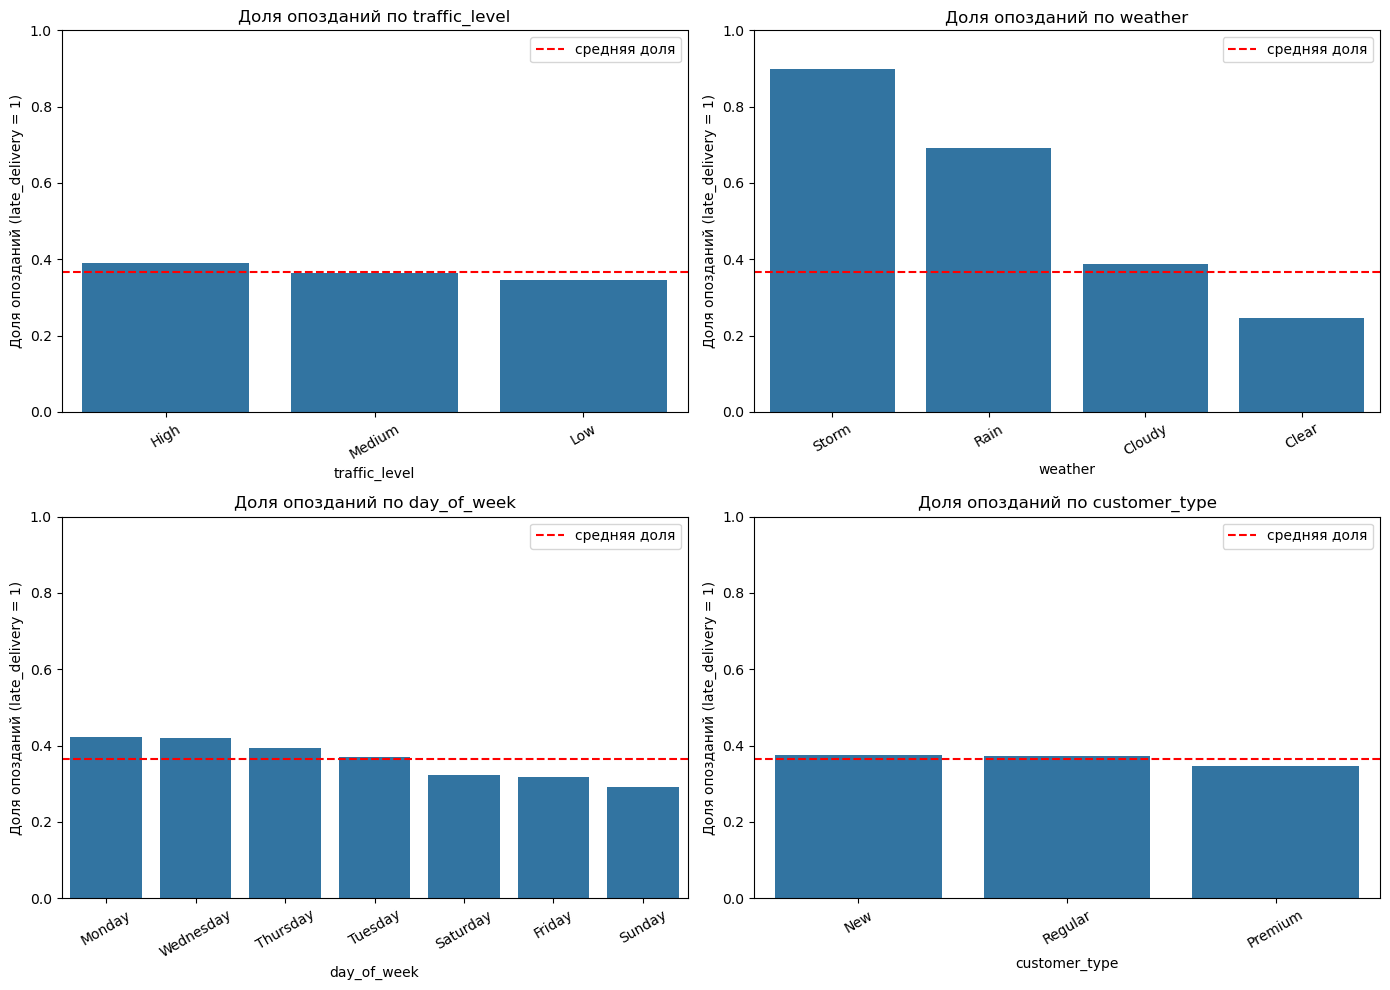

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
cols_to_plot = ['traffic_level', 'weather', 'day_of_week', 'customer_type']

for ax, col in zip(axes.flatten(), cols_to_plot):
    order = train_df.groupby(col)['late_delivery'].mean().sort_values(ascending=False).index
    sns.barplot(x=col, y='late_delivery', data=train_df, order=order, ax=ax, errorbar=None)
    ax.set_title(f'Доля опозданий по {col}')
    ax.set_ylabel('Доля опозданий (late_delivery = 1)')
    ax.set_ylim(0, 1)
    ax.axhline(train_df['late_delivery'].mean(), color='red', linestyle='--', label='средняя доля')
    ax.legend()
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

*Интерпретация визуального анализа*

1. Гистограммы:

Время (order_hour): Два пика — обеденный (12–14 часов) и вечерний (18–20 часов). Это часы пик, когда нагрузка на доставку максимальна, что логично может влиять на опоздания.

Деньги (subtotal, tax_amount, service_fee, order_total): Распределения имеют сильную правостороннюю асимметрию (long tail). Основная масса заказов дешевая (10–50), но есть хвост из очень дорогих заказов (до 400+). Именно из-за этого разброса нормализация будет важна для KNN.

Расстояние (distance_km): Большинство заказов в радиусе 2–6 км. Хвост доходит до 20 км.

Время готовки (restaurant_preparation_time_minutes): Основной пик — 10–15 минут. Но есть "хвост" из ресторанов, где готовят 30–70 минут.

Оценка ресторана (restaurant_rating): Распределение смещено вправо (в сторону 4.0–5.0). Люди редко заказывают в ресторанах с рейтингом ниже 3.5.

2. Выбросы:

На графиках денег (order_total, subtotal, tax_amount, tip_amount) видно большое количество выбросов (точек над усами).

Это не ошибки. Это реальные большие заказы или очень щедрые чаевые. Их не удаляем, так как KNN после нормализации сможет с ними работать, а удаление лишило бы модель информации о поведении на больших чеках.

3. Категориальные признаки:

Количество уникальных значений небольшое (максимум 40 у delivery_area). После OneHotEncoder мы не получим сотни колонок, и KNN будет работать быстро.

В данных присутствует логика: рейтинги ресторанов высокие (средний 4.2), большинство заказов — это фастфуд (Fast Food — 21k) и оплата картой (Credit Card — 19k).

4. Корреляция с целевой переменной (late_delivery):

Главный фактор: restaurant_preparation_time_minutes (корреляция 0.256). Чем дольше готовят — тем чаще опаздывают.

Второстепенные факторы: distance_km (0.095) и estimated_delivery_time_minutes (0.087). Чем дальше ехать и чем дольше расчетное время, тем выше риск.

is_weekend имеет отрицательную корреляцию (−0.073). В выходные курьеры опаздывают реже, чем в будни (возможно, из-за пробок в будние дни или меньшего количества заказов в выходные утром).

Деньги (order_total и др.) почти не коррелируют с опозданием (0.007). Стоимость заказа сама по себе не предсказывает, опоздает курьер или нет.

Самые сильные предикторы опоздания — это weather (разброс доли опозданий от 24.6% при Clear до 89.8% при Storm) и restaurant_preparation_time_minutes (корреляция 0.256). Погода — категориальный признак, поэтому после OneHotEncoder он станет отдельными бинарными колонками.

Второстепенные предикторы: traffic_level (разброс 4.4 п.п.), day_of_week (Monday — 42.4%, Sunday — 29.2%), distance_km (corr 0.095), estimated_delivery_time_minutes (corr 0.087).

Слабые предикторы (≈ среднее): city, delivery_area, customer_type, restaurant_type, payment_method.

Не связаны с таргетом: order_total, subtotal, tax_amount, service_fee, items_count, tip_amount, discount_percent, restaurant_rating, customer_age, delivery_partner_rating, delivery_partner_experience_months. Все они имеют корреляцию с late_delivery меньше 0.02.

5. Матрица корреляции:

Признаки subtotal, tax_amount, service_fee и order_total имеют корреляцию 0.99–1.00. Они несут одну и ту же информацию.

Для kNN это как раз важно: расстояние считается по всем признакам одинаково, поэтому четыре почти одинаковых денежных признака фактически входят в расстояние четыре раза и перетягивают на себя вес, хотя с опозданием не связаны. Для логистической регрессии такие признаки создают мультиколлинеарность (коэффициенты становятся неустойчивыми). Поэтому на шаге оптимизации оставим из них только order_total.

6. Пропущенные значения:

После удаления отмененных заказов пропущенных значений нет




Признак traffic_level порядковый (Low < Medium < High), поэтому он закодирован числами 0/1/2. Остальные номинальные признаки закодированы one-hot (OneHotEncoder), кодировщик обучен только на обучающей выборке, чтобы не допустить утечки информации из теста. В результате получилось 85 признаков.

In [14]:
X_train = X_train.copy()
X_test = X_test.copy()


traffic_map = {'Low': 0, 'Medium': 1, 'High': 2}
X_train['traffic_level'] = X_train['traffic_level'].map(traffic_map)
X_test['traffic_level'] = X_test['traffic_level'].map(traffic_map)

#city дублируется в delivery_area
X_train = X_train.drop(columns='city')
X_test = X_test.drop(columns='city')


nominal_features = ['day_of_week', 'delivery_area', 'customer_type',
                    'restaurant_type', 'restaurant_primary_category',
                    'payment_method', 'weather']

enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
enc.fit(X_train[nominal_features])   # обучаем только на train

def encode(X):
    dummies = pd.DataFrame(enc.transform(X[nominal_features]),
                           columns=enc.get_feature_names_out(nominal_features),
                           index=X.index)
    return pd.concat([X.drop(columns=nominal_features), dummies], axis=1)

X_train = encode(X_train)
X_test = encode(X_test)

numeric_features = [c for c in numeric_features] + ['traffic_level']

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Нечисловых столбцов:", X_train.select_dtypes(include='object').shape[1])
print("Пропусков:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Train: (39305, 85) Test: (9827, 85)
Нечисловых столбцов: 0
Пропусков: 0 0


*Нормализация*

Для метода k ближайших соседей нормализация необходима, так как он опирается на евклидово расстояние: признаки с большим масштабом (суммы заказа, время доставки) доминировали бы над признаками с малым диапазоном (рейтинги, количество блюд). Применяем стандартизацию (StandardScaler) к числовым признакам. Параметры (среднее и стандартное отклонение) вычислены только по обучающей выборке и применены к тестовой, чтобы избежать утечки данных. Бинарные признаки после one-hot кодирования уже принимают значения 0/1.

In [15]:
scaler = StandardScaler()
scaler.fit(X_train[numeric_features])

X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[numeric_features] = scaler.transform(X_train[numeric_features])
X_test_s[numeric_features] = scaler.transform(X_test[numeric_features])

check = pd.DataFrame({
    'train_mean': X_train_s[numeric_features].mean().round(3),
    'train_std':  X_train_s[numeric_features].std().round(3),
    'test_mean':  X_test_s[numeric_features].mean().round(3),
    'test_std':   X_test_s[numeric_features].std().round(3),
})
print(check)

                                     train_mean  train_std  test_mean  \
order_hour                                 -0.0        1.0      0.005   
is_weekend                                  0.0        1.0     -0.016   
customer_age                               -0.0        1.0      0.013   
restaurant_rating                           0.0        1.0     -0.012   
items_count                                 0.0        1.0      0.003   
subtotal                                    0.0        1.0      0.006   
discount_percent                            0.0        1.0      0.010   
tax_amount                                  0.0        1.0      0.005   
service_fee                                -0.0        1.0      0.010   
delivery_fee                               -0.0        1.0      0.002   
order_total                                -0.0        1.0      0.006   
tip_amount                                  0.0        1.0      0.021   
distance_km                                 0.0    

*KNN*

In [16]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

y_train_pred = knn.predict(X_train_s)
y_test_pred = knn.predict(X_test_s)

print(f"Ошибка на train: {1 - accuracy_score(y_train, y_train_pred):.4f}")
print(f"Ошибка на test:  {1 - accuracy_score(y_test, y_test_pred):.4f}")
print(f"Ошибка константного прогноза «не опоздает»: {y_test.mean():.4f}")

print("\nМатрица рассогласования (train):")
print(confusion_matrix(y_train, y_train_pred))
print("\nМатрица рассогласования (test):")
print(confusion_matrix(y_test, y_test_pred))

print("\nОтчёт по тесту:")
print(classification_report(y_test, y_test_pred, target_names=['вовремя', 'опоздал']))

Ошибка на train: 0.2061
Ошибка на test:  0.3132
Ошибка константного прогноза «не опоздает»: 0.3657

Матрица рассогласования (train):
[[22725  2206]
 [ 5896  8478]]

Матрица рассогласования (test):
[[5217 1016]
 [2062 1532]]

Отчёт по тесту:
              precision    recall  f1-score   support

     вовремя       0.72      0.84      0.77      6233
     опоздал       0.60      0.43      0.50      3594

    accuracy                           0.69      9827
   macro avg       0.66      0.63      0.64      9827
weighted avg       0.67      0.69      0.67      9827



Лучшее k по CV-ошибке: 27 | CV-ошибка: 0.29
Лучшее k по CV-F1: 3 | F1: 0.4844


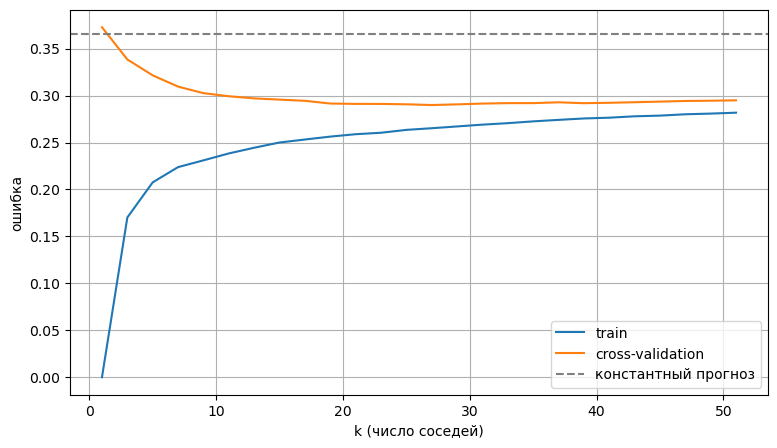

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate

k_values = list(range(1, 52, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_err, cv_err, cv_f1 = [], [], []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    res = cross_validate(model, X_train_s, y_train, cv=cv,
                         scoring=['accuracy', 'f1'],
                         return_train_score=True, n_jobs=-1)
    train_err.append(1 - res['train_accuracy'].mean())
    cv_err.append(1 - res['test_accuracy'].mean())
    cv_f1.append(res['test_f1'].mean())

best_k = k_values[int(np.argmin(cv_err))]
print("Лучшее k по CV-ошибке:", best_k, "| CV-ошибка:", round(min(cv_err), 4))
print("Лучшее k по CV-F1:", k_values[int(np.argmax(cv_f1))], "| F1:", round(max(cv_f1), 4))

plt.figure(figsize=(9, 5))
plt.plot(k_values, train_err, label='train')
plt.plot(k_values, cv_err, label='cross-validation')
plt.axhline(y_train.mean(), color='gray', ls='--', label='константный прогноз')
plt.xlabel('k (число соседей)'); plt.ylabel('ошибка'); plt.legend(); plt.grid()
plt.show()

Классификатор KNN выбран как простой и интерпретируемый метод, который не требует предположений о форме зависимости и хорошо подходит в качестве базовой модели. При k=5 ошибка на обучающей выборке (0,21) ниже, чем на тестовой (0,313): модель переобучается, а при k=1 ошибка на train равна нулю. Оптимальное k выбиралось кросс-валидацией (5 фолдов) на обучающей выборке: минимум CV-ошибки достигается при k=27 (≈0,29), после чего кривая выходит на плато. По F1 для класса «опоздал» лучшим оказалось k=3, но оно даёт больше ошибок в целом, поэтому выбрано k=27. Модель лучше константного прогноза (ошибка 0,366), но выигрыш умеренный. По матрице рассогласования видно, что модель хорошо распознаёт вовремя доставленные заказы, но находит менее половины опозданий (recall ≈ 0,31): большая часть ошибок приходится на ложные «вовремя».

In [18]:
best_k = 27
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_s, y_train)

y_train_pred = knn_best.predict(X_train_s)
y_test_pred = knn_best.predict(X_test_s)

print(f"k = {best_k}")
print(f"Ошибка на train: {1 - accuracy_score(y_train, y_train_pred):.4f}")
print(f"Ошибка на test:  {1 - accuracy_score(y_test, y_test_pred):.4f}")

print("\nМатрица рассогласования (train):")
print(confusion_matrix(y_train, y_train_pred))
print("\nМатрица рассогласования (test):")
print(confusion_matrix(y_test, y_test_pred))

print("\nОтчёт по тесту:")
print(classification_report(y_test, y_test_pred, target_names=['вовремя', 'опоздал']))

k = 27
Ошибка на train: 0.2626
Ошибка на test:  0.2831

Матрица рассогласования (train):
[[23946   985]
 [ 9338  5036]]

Матрица рассогласования (test):
[[5924  309]
 [2473 1121]]

Отчёт по тесту:
              precision    recall  f1-score   support

     вовремя       0.71      0.95      0.81      6233
     опоздал       0.78      0.31      0.45      3594

    accuracy                           0.72      9827
   macro avg       0.74      0.63      0.63      9827
weighted avg       0.73      0.72      0.68      9827



Уберем лишние признаки

A: все признаки: 85 признаков, лучшее k = 27, CV-ошибка = 0.2900
B: без коррелированных: 82 признаков, лучшее k = 27, CV-ошибка = 0.2905
C: только информативные: 10 признаков, лучшее k = 11, CV-ошибка = 0.2027


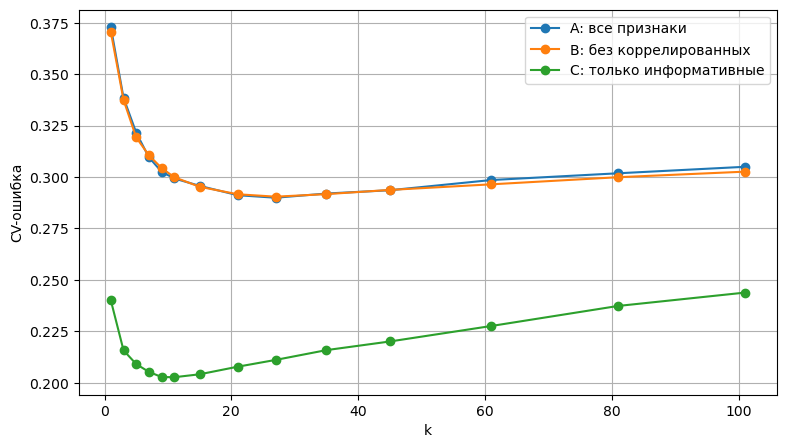

In [ ]:
all_cols = X_train_s.columns.tolist()

set_A = all_cols
set_B = [c for c in all_cols if c not in ['subtotal', 'tax_amount', 'service_fee']]
weather_cols = [c for c in all_cols if c.startswith('weather_')]
set_C = weather_cols + ['restaurant_preparation_time_minutes', 'distance_km',
                        'estimated_delivery_time_minutes', 'delivery_fee',
                        'is_weekend', 'traffic_level']

feature_sets = {'A: все признаки': set_A,
                'B: без коррелированных': set_B,
                'C: только информативные': set_C}

k_values = [1, 3, 5, 7, 9, 11, 15, 21, 27, 35, 45, 61, 81, 101]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}
for name, cols in feature_sets.items():
    cv_err = []
    for k in k_values:
        res = cross_validate(KNeighborsClassifier(n_neighbors=k),
                             X_train_s[cols], y_train, cv=cv,
                             scoring='accuracy', n_jobs=-1)
        cv_err.append(1 - res['test_score'].mean())
    best_k = k_values[int(np.argmin(cv_err))]
    results[name] = (best_k, min(cv_err), cv_err)
    print(f"{name}: {len(cols)} признаков, лучшее k = {best_k}, CV-ошибка = {min(cv_err):.4f}")

plt.figure(figsize=(9, 5))
for name, (bk, me, errs) in results.items():
    plt.plot(k_values, errs, marker='o', label=name)
plt.xlabel('k'); plt.ylabel('CV-ошибка'); plt.legend(); plt.grid()
plt.show()

In [ ]:
for name, cols in feature_sets.items():
    k = results[name][0]
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s[cols], y_train)
    pred = m.predict(X_test_s[cols])
    rep = classification_report(y_test, pred, output_dict=True)
    print(f"{name} (k={k}): ошибка test = {1 - accuracy_score(y_test, pred):.4f}, "
          f"recall(опоздал) = {rep['1']['recall']:.2f}, "
          f"precision(опоздал) = {rep['1']['precision']:.2f}, "
          f"F1(опоздал) = {rep['1']['f1-score']:.2f}")
    print(confusion_matrix(y_test, pred))

A: все признаки (k=27): ошибка test = 0.2831, recall(опоздал) = 0.31, precision(опоздал) = 0.78, F1(опоздал) = 0.45
[[5924  309]
 [2473 1121]]
B: без коррелированных (k=27): ошибка test = 0.2856, recall(опоздал) = 0.32, precision(опоздал) = 0.77, F1(опоздал) = 0.45
[[5887  346]
 [2461 1133]]
C: только информативные (k=11): ошибка test = 0.2015, recall(опоздал) = 0.66, precision(опоздал) = 0.76, F1(опоздал) = 0.71
[[5470  763]
 [1217 2377]]


Были сравнены три набора признаков для KNN. (A) все 85 признаков; (B) без subtotal, tax_amount, service_fee, которые имеют корреляцию 0,99+ с order_total и несут ту же информацию; (C) только 10 информативных признаков: погода, время приготовления, расстояние, расчётное время доставки, стоимость доставки, выходной день и загруженность дорог. Набор B дал то же качество, что и A (ошибка на тесте 0,286 против 0,283), поэтому коррелированные признаки можно исключить без потерь: модель становится проще и быстрее. Набор C существенно улучшил результат: ошибка на тесте снизилась до 0,2015, recall для класса «опоздал» вырос с 0,31 до 0,66, F1 с 0,45 до 0,71. Причина в том, что KNN опирается на расстояния, и при большом числе малоинформативных признаков (чаевые, возраст клиента, тип оплаты и т.д.) они зашумляют расстояние и отвлекают от по-настоящему важных (погода, время готовки). Оптимальное k при этом уменьшилось с 27 до 11.

*Сравнение с другими методами*

In [23]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_pipe(clf, cols, scale=True):
    """Pipeline: стандартизация числовых признаков (только по обучающим данным) + модель."""
    num = [c for c in cols if c in numeric_features]
    scaler = StandardScaler() if scale else 'passthrough'
    prep = ColumnTransformer([('num', scaler, num)], remainder='passthrough')
    return Pipeline([('prep', prep), ('clf', clf)])

In [24]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 27, 35, 45, 61, 81, 101]

grid = GridSearchCV(make_pipe(KNeighborsClassifier(), set_C),
                    param_grid={'clf__n_neighbors': k_values},
                    cv=cv, scoring='accuracy', n_jobs=-1)
grid.fit(X_train[set_C], y_train)
best_k_C = grid.best_params_['clf__n_neighbors']
print("Лучшее k на наборе C (Pipeline):", best_k_C, "| CV-ошибка:", round(1 - grid.best_score_, 4))

set_C_nofee = [c for c in set_C if c != 'delivery_fee']
grid_nf = GridSearchCV(make_pipe(KNeighborsClassifier(), set_C_nofee),
                       param_grid={'clf__n_neighbors': k_values},
                       cv=cv, scoring='accuracy', n_jobs=-1)
grid_nf.fit(X_train[set_C_nofee], y_train)
print("C с delivery_fee:   CV-ошибка =", round(1 - grid.best_score_, 4))
print("C без delivery_fee: CV-ошибка =", round(1 - grid_nf.best_score_, 4))
print("corr(delivery_fee, distance_km)   =", round(X_train['delivery_fee'].corr(X_train['distance_km']), 3))
print("corr(delivery_fee, late_delivery) =", round(X_train['delivery_fee'].corr(y_train), 3))

Лучшее k на наборе C (Pipeline): 11 | CV-ошибка: 0.2026
C с delivery_fee:   CV-ошибка = 0.2026
C без delivery_fee: CV-ошибка = 0.1921
corr(delivery_fee, distance_km)   = 0.408
corr(delivery_fee, late_delivery) = 0.062


In [25]:
all_cols = X_train.columns.tolist()
rf_params = dict(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)

experiments = {
    f'kNN (набор C, k={best_k_C})':  (make_pipe(KNeighborsClassifier(n_neighbors=best_k_C), set_C), set_C),
    'Лог. регрессия (набор C)':      (make_pipe(LogisticRegression(max_iter=2000), set_C), set_C),
    'Случайный лес (набор C)':       (make_pipe(RandomForestClassifier(**rf_params), set_C, scale=False), set_C),
    'kNN (все признаки, k=27)':      (make_pipe(KNeighborsClassifier(n_neighbors=27), all_cols), all_cols),
    'Лог. регрессия (все признаки)': (make_pipe(LogisticRegression(max_iter=2000), all_cols), all_cols),
    'Случайный лес (все признаки)':  (make_pipe(RandomForestClassifier(**rf_params), all_cols, scale=False), all_cols),
}

rows = []
for name, (pipe, cols) in experiments.items():
    pipe.fit(X_train[cols], y_train)
    pred_tr = pipe.predict(X_train[cols])
    pred = pipe.predict(X_test[cols])
    proba = pipe.predict_proba(X_test[cols])[:, 1]
    rows.append({'модель': name,
                 'ошибка train': 1 - accuracy_score(y_train, pred_tr),
                 'ошибка test': 1 - accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred),
                 'recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred),
                 'ROC-AUC': roc_auc_score(y_test, proba)})
    if 'набор C' in name:
        print(name); print(confusion_matrix(y_test, pred)); print()

print(pd.DataFrame(rows).set_index('модель').round(3).to_string())

kNN (набор C, k=11)
[[5470  763]
 [1217 2377]]

Лог. регрессия (набор C)
[[5470  763]
 [1130 2464]]

Случайный лес (набор C)
[[5546  687]
 [1173 2421]]

                               ошибка train  ошибка test  precision  recall     F1  ROC-AUC
модель                                                                                     
kNN (набор C, k=11)                   0.165        0.201      0.757   0.661  0.706    0.869
Лог. регрессия (набор C)              0.199        0.193      0.764   0.686  0.722    0.875
Случайный лес (набор C)               0.118        0.189      0.779   0.674  0.722    0.882
kNN (все признаки, k=27)              0.263        0.283      0.784   0.312  0.446    0.772
Лог. регрессия (все признаки)         0.173        0.173      0.782   0.731  0.756    0.905
Случайный лес (все признаки)          0.080        0.187      0.815   0.630  0.711    0.889


Сравнение на одинаковом наборе признаков (набор C). Три модели сопоставимы: ошибка на тесте 0,189–0,201, F1 для класса «опоздал» 0,706–0,722, ROC-AUC 0,869–0,882. Небольшое преимущество у случайного леса (ошибка 0,189, AUC 0,882) и логистической регрессии (F1 0,722), но на тесте из примерно 9,8 тыс. наблюдений разница в 0,01 близка к статистическому шуму (стандартная ошибка оценки около 0,004), поэтому уверенно ранжировать эти модели нельзя. kNN немного уступает по ROC-AUC и recall (0,661 против 0,686 у логистической регрессии).

Для kNN отбор признаков критичен: переход от всех признаков (k=27) к набору C снижает ошибку на тесте с 0,283 до 0,201, повышает recall с 0,312 до 0,661, F1 — с 0,446 до 0,706, ROC-AUC — с 0,772 до 0,869. Причина в том, что kNN опирается на расстояния, а множество малоинформативных признаков зашумляет их. Логистическая регрессия, напротив, работает лучше на всех признаках, чем на наборе C (ошибка 0,173 против 0,193, F1 0,756 против 0,722, ROC-AUC 0,905 против 0,875): значит, набор C потерял часть полезной информации. Вероятно, это признаки, на которые указывал анализ, но которые в набор не вошли (например, день недели: доля опозданий от 29,2% в воскресенье до 42,4% в понедельник). Случайный лес почти не зависит от набора признаков (ошибка 0,187 и 0,189): он сам отбирает значимые признаки.

Случайный лес переобучается (ошибка на train 0,118 и 0,080 против 0,189 и 0,187 на test), kNN переобучен умеренно (0,165 против 0,201). У логистической регрессии на всех признаках ошибки на train и test совпадают (0,173), переобучения нет.

Итог - лучшая модель по всем метрикам - логистическая регрессия на всех признаках (ошибка 0,173, F1 0,756, ROC-AUC 0,905), и при этом она проще и быстрее остальных. Все модели лучше константного прогноза (ошибка 0,366), но пропускают заметную долю опозданий: recall 0,63–0,73, а у kNN на всех признаках лишь 0,31. По матрицам рассогласования на тесте для набора C пропущенных опозданий больше, чем ложных тревог (1130–1217 против 687–763). Precision выше recall (0,76–0,82), то есть если модель предупреждает об опоздании, она чаще права, чем нет. Вероятно, зависимость близка к линейной по логарифму шансов, поэтому линейная модель справляется не хуже более сложных.

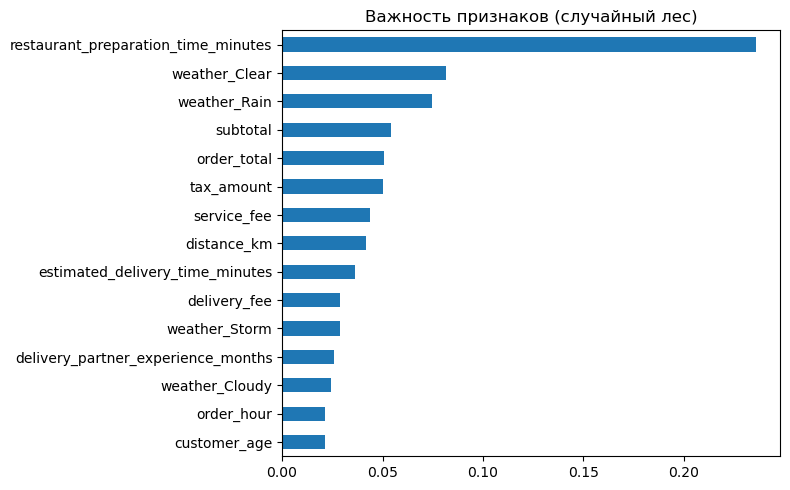

In [26]:
rf_pipe = experiments['Случайный лес (все признаки)'][0]
rf = rf_pipe.named_steps['clf']
names = [n.split('__', 1)[1] for n in rf_pipe.named_steps['prep'].get_feature_names_out()]
imp = pd.Series(rf.feature_importances_, index=names).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 5))
imp[::-1].plot(kind='barh')
plt.title('Важность признаков (случайный лес)')
plt.tight_layout(); plt.show()

Главный признак по важности для случайного леса — время приготовления заказа (около 0,23), затем идут погодные признаки (weather_Clear, weather_Rain), что согласуется с анализом корреляций и долей опозданий по категориям. Заметная важность денежных признаков (subtotal, order_total, tax_amount, service_fee) не означает реального влияния: их корреляция с целевой переменной близка к нулю. Важность, основанная на уменьшении неоднородности (impurity), смещена в пользу непрерывных признаков с большим числом значений. Кроме того, эти четыре признака дублируют друг друга, и важность делится между ними.

In [27]:
from sklearn.model_selection import cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


lr_base = LogisticRegression(max_iter=2000).fit(X_train_s, y_train)
proba_test = lr_base.predict_proba(X_test_s)[:, 1]
pred_base = (proba_test >= 0.5).astype(int)


lr_bal = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X_train_s, y_train)
pred_bal = lr_bal.predict(X_test_s)


proba_cv = cross_val_predict(LogisticRegression(max_iter=2000), X_train_s, y_train,
                             cv=cv, method='predict_proba')[:, 1]
thresholds = np.arange(0.20, 0.71, 0.01)
f1_cv = [f1_score(y_train, (proba_cv >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(f1_cv))]
print(f"Лучший порог по CV-F1: {best_t:.2f}")
pred_thr = (proba_test >= best_t).astype(int)

rows = []
for name, pred in [('порог 0.5 (базовая)', pred_base),
                   ('class_weight=balanced', pred_bal),
                   (f'порог {best_t:.2f} (по CV)', pred_thr)]:
    rows.append({'вариант': name,
                 'ошибка test': 1 - accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred),
                 'recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred)})
    print(name); print(confusion_matrix(y_test, pred)); print()
print(pd.DataFrame(rows).set_index('вариант').round(3).to_string())

Лучший порог по CV-F1: 0.37
порог 0.5 (базовая)
[[5502  731]
 [ 967 2627]]

class_weight=balanced
[[5061 1172]
 [ 638 2956]]

порог 0.37 (по CV)
[[5078 1155]
 [ 644 2950]]

                       ошибка test  precision  recall     F1
вариант                                                     
порог 0.5 (базовая)          0.173      0.782   0.731  0.756
class_weight=balanced        0.184      0.716   0.822  0.766
порог 0.37 (по CV)           0.183      0.719   0.821  0.766


Классы несбалансированы умеренно: доля опоздавших заказов около 37% против 63% доставленных вовремя, поэтому сильного эффекта от балансировки нет. Для логистической регрессии на всех признаках были проверены два способа сместить решение в сторону класса «опоздал»: веса классов (class_weight='balanced') и подбор порога вероятности по кросс-валидации на обучающей выборке (лучший порог по F1 — 0,37, тест при этом не использовался).

Оба способа дали почти одинаковый результат. По сравнению с порогом 0,5 recall вырос с 0,731 до 0,822 (веса) и 0,821 (порог): число пропущенных опозданий на тесте сократилось с 967 до 638–644. Платой стало снижение precision с 0,782 до 0,716–0,719 (ложных стало 1155–1172 вместо 731) и рост общей ошибки с 0,173 до 0,183–0,184. F1 для класса «опоздал» улучшился незначительно: с 0,756 до 0,766.

Таким образом, борьба с дисбалансом не улучшает модель «вообще», а меняет компромисс между ошибками двух типов. Если важнее не пропустить опоздание (например, чтобы заранее предупредить клиента), стоит использовать порог 0,37: он даёт тот же результат, что и веса классов, но не требует переобучения модели. Если важнее точность предупреждений и минимум ложных тревог, лучше оставить порог 0,5.

*Выводы*

Решалась задача бинарной классификации: предсказать, опоздает ли доставка (late_delivery), по данным о заказе, ресторане, погоде, трафике и курьере. После удаления отменённых заказов в данных осталось около 49 тыс. наблюдений, доля опоздавших — около 37%, то есть классы несбалансированы умеренно. Ошибка константного прогноза «не опоздает» равна 0,366.

Главные факторы опоздания — погода. Второстепенные — расстояние, расчётное время доставки и день недели. Денежные признаки, возраст клиента и тип оплаты практически не связаны с опозданием.

kNN на всех признаках работает слабо (k=27, ошибка на тесте 0,283, recall 0,312, ROC-AUC 0,772): множество малоинформативных признаков зашумляет расстояния. Исключение коррелированных денежных признаков качество не изменило, а оставление информативных признаков (набор C) заметно улучшило модель: при k=11 ошибка 0,201, recall 0,661, F1 0,706, ROC-AUC 0,869. Оптимальное k выбиралось кросс-валидацией на обучающей выборке.

Лучшей моделью стала логистическая регрессия на всех признаках: ошибка на тесте 0,173, F1 0,756, ROC-AUC 0,905, без переобучения (ошибки на train и test совпадают). Она лучше kNN и случайного леса (ошибка 0,187, переобучается: 0,080 на train), при этом проще и быстрее. Вероятно, зависимость близка к линейной по логарифму шансов. На наборе C все три модели сопоставимы (ошибка 0,189–0,201), различия на уровне статистического шума.

Ограничения: результаты получены на одном датасете и одном разбиении на train/test; использованы признаки (время приготовления, расчётное время доставки), известные только непосредственно перед доставкой; гиперпараметры логистической регрессии и случайного леса не подбирались.